In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

path = kagglehub.dataset_download("redwankarimsony/heart-disease-data")
print(os.listdir(path))
df = pd.read_csv(os.path.join(path, "heart_disease_uci.csv"))

print("Shape:", df.shape)
display(df.head(10))
print("\nMissing values:\n", df.isnull().sum())
print("\nTarget (num) distribution:\n", df["num"].value_counts().sort_index())

c:\Users\DELL\OneDrive\Desktop\University\Machine Learnng\Labs\PyCharmMiscProject\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 12.4k/12.4k [00:00<00:00, 2.33MB/s]

Extracting files...
['heart_disease_uci.csv']
Shape: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
5,6,56,Male,Cleveland,atypical angina,120.0,236.0,False,normal,178.0,False,0.8,upsloping,0.0,normal,0
6,7,62,Female,Cleveland,asymptomatic,140.0,268.0,False,lv hypertrophy,160.0,False,3.6,downsloping,2.0,normal,3
7,8,57,Female,Cleveland,asymptomatic,120.0,354.0,False,normal,163.0,True,0.6,upsloping,0.0,normal,0
8,9,63,Male,Cleveland,asymptomatic,130.0,254.0,False,lv hypertrophy,147.0,False,1.4,flat,1.0,reversable defect,2
9,10,53,Male,Cleveland,asymptomatic,140.0,203.0,True,lv hypertrophy,155.0,True,3.1,downsloping,0.0,reversable defect,1



Missing values:
 id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

Target (num) distribution:
 num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64


In [2]:
data = df.copy()

# Useless ID column drop
data = data.drop(columns=["id"])

# Binary target: 0 = no disease, 1 = disease
data["target"] = (data["num"] > 0).astype(int)
data = data.drop(columns=["num"])
print("Binary target distribution:\n", data["target"].value_counts())

# Missing values: numeric -> median, categorical -> mode
num_cols = data.select_dtypes(include="number").columns.drop("target")
cat_cols = data.select_dtypes(exclude="number").columns

for c in num_cols:
    data[c] = data[c].fillna(data[c].median())
for c in cat_cols:
    data[c] = data[c].fillna(data[c].mode()[0])

# Encoding: one-hot for categorical (fbs, exang bool bhi isi mein aate hain)
data = pd.get_dummies(data, columns=list(cat_cols), drop_first=True, dtype=int)

print("\nRemaining missing:", data.isnull().sum().sum())
print("Shape after encoding:", data.shape)

Binary target distribution:
 target
1    509
0    411
Name: count, dtype: int64

Remaining missing: 0
Shape after encoding: (920, 22)


In [3]:
X = data.drop("target", axis=1)
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (736, 21) Test: (184, 21)


In [4]:
rf_base = RandomForestClassifier(random_state=42)
rf_base.fit(X_train, y_train)
base_acc = accuracy_score(y_test, rf_base.predict(X_test))
print(f"Baseline test accuracy: {base_acc:.4f}")

Baseline test accuracy: 0.8533


In [5]:
param_grid = {
    "n_estimators":      [100, 200],
    "max_depth":         [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf":  [1, 2],
    "max_features":      ["sqrt", "log2"],
}

grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)

print("Best hyperparameters:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best hyperparameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best CV accuracy: 0.8220


,Metric,Value
0,Accuracy,0.8478
1,Precision,0.8426
2,Recall,0.8922
3,F1-score,0.8667


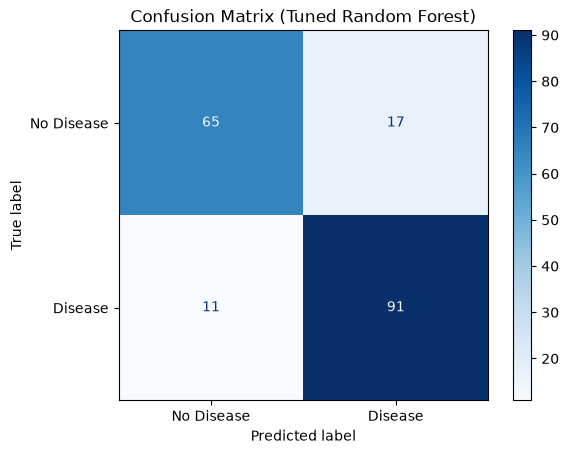

Baseline: 0.8533  ->  Tuned: 0.8478


In [6]:
best_rf = grid.best_estimator_
y_pred = best_rf.predict(X_test)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Value": [accuracy_score(y_test, y_pred),
              precision_score(y_test, y_pred),
              recall_score(y_test, y_pred),
              f1_score(y_test, y_pred)],
}).round(4)
display(metrics)

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["No Disease", "Disease"]).plot(cmap="Blues")
plt.title("Confusion Matrix (Tuned Random Forest)")
plt.show()

print(f"Baseline: {base_acc:.4f}  ->  Tuned: {accuracy_score(y_test, y_pred):.4f}")

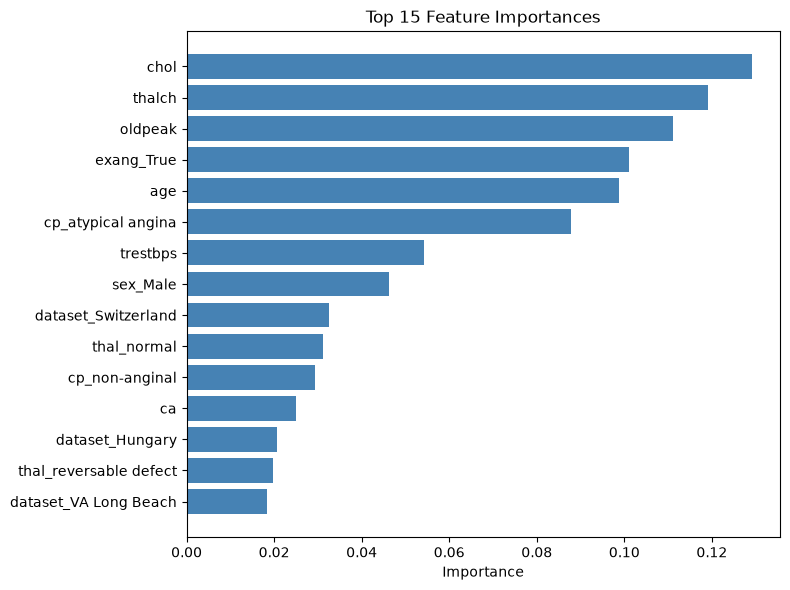

Top 3 most influential features:
chol       0.1291
thalch     0.1191
oldpeak    0.1111
dtype: float64


In [7]:
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)

top = importances.head(15)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color="steelblue")
plt.xlabel("Importance")
plt.title("Top 15 Feature Importances")
plt.tight_layout()
plt.show()

print("Top 3 most influential features:")
print(importances.head(3).round(4))